In [69]:

# ==========================================
# UTS MACHINE LEARNING
# Nama  : (Isi nama Anda)
# NIM   : 2301010265
# SEED  : 265
# Jalur : A - Klasifikasi
# ==========================================

# Menentukan nilai random seed
SEED = 265

print("UTS MACHINE LEARNING")
print("NIM:", "2301010265")
print("SEED:", SEED)
print("Jalur: Klasifikasi")


UTS MACHINE LEARNING
NIM: 2301010265
SEED: 265
Jalur: Klasifikasi


In [70]:

# ==========================================
# 1. MENGUNDUH DATASET DARI UCI
# ==========================================

import requests
import zipfile
import io
import os

# Link resmi dataset UCI
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

# Mengunduh file ZIP
response = requests.get(url)
response.raise_for_status()

# Membaca file ZIP
zip_data = zipfile.ZipFile(io.BytesIO(response.content))

# Melihat daftar file di dalam ZIP
print("Daftar file dalam ZIP:")
for file in zip_data.namelist():
    print(file)


Daftar file dalam ZIP:
bank.zip
bank-additional.zip


In [71]:

# ==========================================
# 3. MENGAMBIL FILE bank.csv
# ==========================================

# Mencari file bank.csv
bank_file = [
    name for name in bank_zip.namelist()
    if name.endswith("bank.csv")
]

if not bank_file:
    raise FileNotFoundError("bank.csv tidak ditemukan!")

# Mengekstrak file
bank_zip.extract(bank_file[0], "/content")

# Menentukan lokasi file
file_path = os.path.join(
    "/content",
    bank_file[0]
)

print("Dataset berhasil diekstrak!")
print("Lokasi:", file_path)


Dataset berhasil diekstrak!
Lokasi: /content/bank.csv


In [72]:

# ==========================================
# 3. MEMBACA DATASET
# ==========================================

import pandas as pd

# Membaca dataset
df = pd.read_csv(file_path, sep=';')

# Menampilkan 5 baris pertama
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [73]:

# ==========================================
# 4. MEMERIKSA UKURAN DATASET
# ==========================================

print("Jumlah baris dan kolom:")
print(df.shape)

print("\nJumlah baris:")
print(df.shape[0])

print("\nJumlah kolom:")
print(df.shape[1])


Jumlah baris dan kolom:
(4521, 17)

Jumlah baris:
4521

Jumlah kolom:
17


In [74]:

# ==========================================
# 5. INFORMASI DATASET
# ==========================================

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [75]:

# ==========================================
# 6. STATISTIK DESKRIPTIF
# ==========================================

df.describe(include='all')


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
count,4521.000000,4521,4521,4521,4521,4521.000000,4521,4521,4521,4521.000000,4521,4521.000000,4521.000000,4521.000000,4521.000000,4521,4521
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,management,married,secondary,no,NaN,yes,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,969,2797,2306,4445,NaN,2559,3830,2896,NaN,1398,NaN,NaN,NaN,NaN,3705,4000
mean,41.170095,NaN,NaN,NaN,NaN,1422.657819,NaN,NaN,NaN,15.915284,NaN,263.961292,2.793630,39.766645,0.542579,NaN,NaN
std,10.576211,NaN,NaN,NaN,NaN,3009.638142,NaN,NaN,NaN,8.247667,NaN,259.856633,3.109807,100.121124,1.693562,NaN,NaN
min,19.000000,NaN,NaN,NaN,NaN,-3313.000000,NaN,NaN,NaN,1.000000,NaN,4.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,33.000000,NaN,NaN,NaN,NaN,69.000000,NaN,NaN,NaN,9.000000,NaN,104.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,444.000000,NaN,NaN,NaN,16.000000,NaN,185.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,49.000000,NaN,NaN,NaN,NaN,1480.000000,NaN,NaN,NaN,21.000000,NaN,329.000000,3.000000,-1.000000,0.000000,NaN,NaN


In [76]:

# ==========================================
# 7. MEMERIKSA TARGET
# ==========================================

print("Distribusi target:")
print(df['y'].value_counts())

print("\nPersentase target:")
print(df['y'].value_counts(normalize=True) * 100)


Distribusi target:
y
no     4000
yes     521
Name: count, dtype: int64

Persentase target:
y
no     88.476001
yes    11.523999
Name: proportion, dtype: float64


In [77]:

# ==========================================
# 8. MEMERIKSA KUALITAS DATA
# ==========================================

print("Missing Value:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())


Missing Value:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Jumlah data duplikat:
0


In [78]:
print("Ukuran dataset:", df.shape)

print("\nInformasi dataset:")
df.info()

print("\nDistribusi target:")
print(df['y'].value_counts())

print("\nMissing value:")
print(df.isnull().sum())

print("\nDuplikat:")
print(df.duplicated().sum())

Ukuran dataset: (4521, 17)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB

Distribusi target:
y
no     4000
yes     521
Name: 

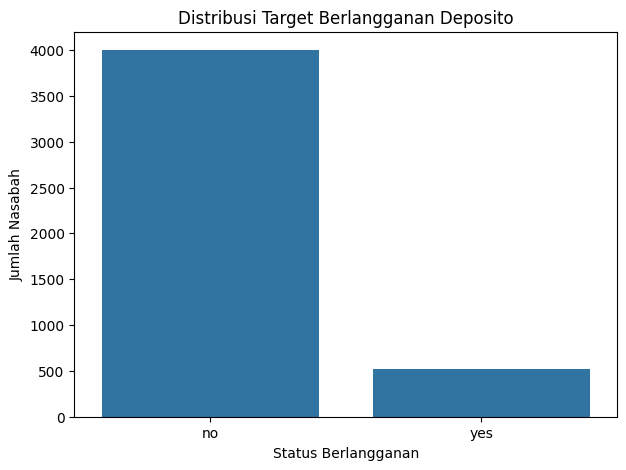

In [79]:

# ==========================================
# EDA 1. DISTRIBUSI TARGET
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='y'
)

plt.title('Distribusi Target Berlangganan Deposito')
plt.xlabel('Status Berlangganan')
plt.ylabel('Jumlah Nasabah')

plt.show()


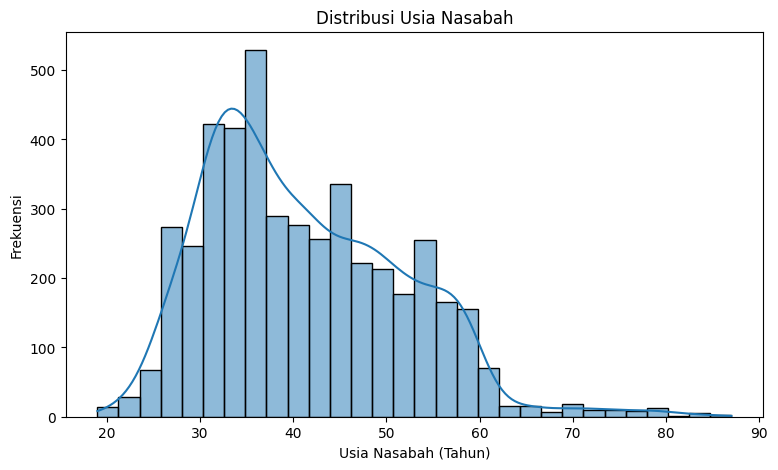

In [80]:

# ==========================================
# EDA 2. DISTRIBUSI USIA NASABAH
# ==========================================

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='age',
    bins=30,
    kde=True
)

plt.title('Distribusi Usia Nasabah')
plt.xlabel('Usia Nasabah (Tahun)')
plt.ylabel('Frekuensi')

plt.show()


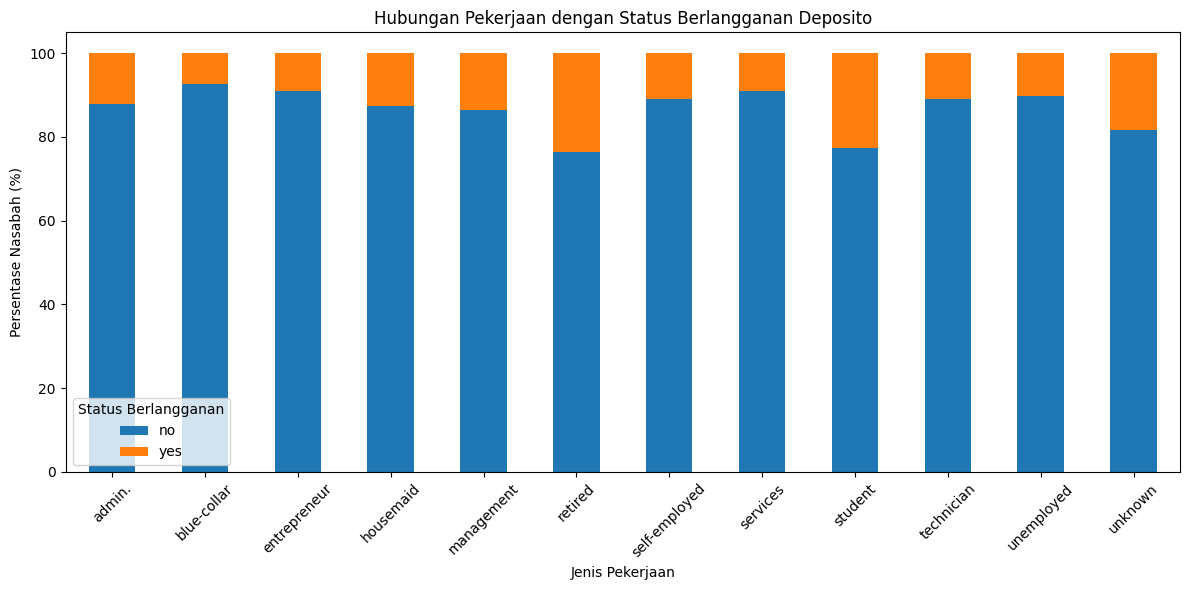

In [81]:

# ==========================================
# EDA 3. HUBUNGAN PEKERJAAN DENGAN TARGET
# ==========================================

# Menghitung persentase target pada setiap pekerjaan
job_target = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

# Membuat grafik
job_target.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Hubungan Pekerjaan dengan Status Berlangganan Deposito')
plt.xlabel('Jenis Pekerjaan')
plt.ylabel('Persentase Nasabah (%)')
plt.legend(title='Status Berlangganan')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [82]:

# ==========================================
# PREPROCESSING 1: MEMERIKSA UNKNOWN
# ==========================================

# Mengambil kolom kategorikal
kolom_kategori = df.select_dtypes(
    include='object'
).columns

# Menghitung jumlah unknown
for kolom in kolom_kategori:
    jumlah_unknown = (df[kolom] == 'unknown').sum()

    if jumlah_unknown > 0:
        print(kolom, ":", jumlah_unknown)


job : 38
education : 187
contact : 1324
poutcome : 3705


In [83]:

# ==========================================
# PREPROCESSING 2: PEMERIKSAAN OUTLIER IQR
# ==========================================

# Memilih kolom numerik
kolom_numerik = df.select_dtypes(
    include='number'
).columns

# Menghitung outlier menggunakan IQR
for kolom in kolom_numerik:

    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    outlier = df[
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ]

    print("Kolom:", kolom)
    print("Jumlah outlier:", len(outlier))
    print("--------------------------")


Kolom: age
Jumlah outlier: 38
--------------------------
Kolom: balance
Jumlah outlier: 506
--------------------------
Kolom: day
Jumlah outlier: 0
--------------------------
Kolom: duration
Jumlah outlier: 330
--------------------------
Kolom: campaign
Jumlah outlier: 318
--------------------------
Kolom: pdays
Jumlah outlier: 816
--------------------------
Kolom: previous
Jumlah outlier: 816
--------------------------


In [84]:

# ==========================================
# PREPROCESSING 3: MEMISAHKAN FITUR DAN TARGET
# ==========================================

# Memisahkan target
y = df['y']

# Menghapus target dan duration dari fitur
X = df.drop(
    columns=['y', 'duration']
)

print("Jumlah fitur:", X.shape[1])
print("Jumlah target:", y.shape[0])

print("\nNama fitur:")
print(X.columns.tolist())


Jumlah fitur: 15
Jumlah target: 4521

Nama fitur:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


In [85]:

# ==========================================
# PREPROCESSING 4: TRAIN TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=SEED
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

print("\nDistribusi target data latih:")
print(y_train.value_counts())

print("\nDistribusi target data uji:")
print(y_test.value_counts())


Jumlah data latih: 3616
Jumlah data uji: 905

Distribusi target data latih:
y
no     3199
yes     417
Name: count, dtype: int64

Distribusi target data uji:
y
no     801
yes    104
Name: count, dtype: int64


In [86]:

# ==========================================
# PREPROCESSING 5: PIPELINE
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Mengidentifikasi kolom numerik dan kategorikal
numerik = X.select_dtypes(
    include='number'
).columns.tolist()

kategorikal = X.select_dtypes(
    include='object'
).columns.tolist()

# Pipeline untuk data numerik
pipeline_numerik = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Pipeline untuk data kategorikal
pipeline_kategorikal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerik, numerik),
        ('cat', pipeline_kategorikal, kategorikal)
    ]
)

print("Kolom numerik:", numerik)
print("Kolom kategorikal:", kategorikal)

print("\nPreprocessing berhasil disiapkan!")


Kolom numerik: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Kolom kategorikal: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Preprocessing berhasil disiapkan!


In [87]:

# ==========================================
# PREPROCESSING 6: VALIDASI PEMBAGIAN DATA
# ==========================================

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)

print("\nProporsi target data latih:")
print(y_train.value_counts(normalize=True) * 100)

print("\nProporsi target data uji:")
print(y_test.value_counts(normalize=True) * 100)

print("\nSEED yang digunakan:", SEED)


Ukuran X_train: (3616, 15)
Ukuran X_test : (905, 15)

Proporsi target data latih:
y
no     88.46792
yes    11.53208
Name: proportion, dtype: float64

Proporsi target data uji:
y
no     88.508287
yes    11.491713
Name: proportion, dtype: float64

SEED yang digunakan: 265


In [88]:

# ==========================================
# MODELING 1: IMPORT LIBRARY
# ==========================================

from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    make_scorer
)

import pandas as pd
import numpy as np

print("Library pemodelan berhasil diimpor!")


Library pemodelan berhasil diimpor!


In [89]:

# ==========================================
# MODELING 2: MEMBUAT MODEL SVM
# ==========================================

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1,
        class_weight='balanced',
        random_state=SEED
    ))
])

print("Model SVM berhasil dibuat!")
print(svm_model)


Model SVM berhasil dibuat!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'day',
                                                   'campaign', 'pdays',
                                                   'previous']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
   

In [90]:

# ==========================================
# MODELING 3: MEMBUAT BASELINE
# ==========================================

dummy_model = DummyClassifier(
    strategy='most_frequent'
)

print("DummyClassifier berhasil dibuat!")
print(dummy_model)


DummyClassifier berhasil dibuat!
DummyClassifier(strategy='most_frequent')


In [91]:

# ==========================================
# MODELING 4: 5-FOLD CROSS VALIDATION
# ==========================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("Cross-validation:", cv)
print("Jumlah fold:", cv.get_n_splits())
print("SEED:", SEED)


Cross-validation: StratifiedKFold(n_splits=5, random_state=265, shuffle=True)
Jumlah fold: 5
SEED: 265


In [92]:

# ==========================================
# MODELING 5: MENENTUKAN METRIK CV
# ==========================================

scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_yes': make_scorer(
        f1_score,
        pos_label='yes'
    )
}

print("Metrik evaluasi berhasil disiapkan!")


Metrik evaluasi berhasil disiapkan!


In [93]:

# ==========================================
# MODELING 6: CROSS VALIDATION SVM
# ==========================================

hasil_svm = cross_validate(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Cross-validation SVM selesai!")


Cross-validation SVM selesai!


In [94]:

# ==========================================
# MODELING 7: CROSS VALIDATION DUMMY
# ==========================================

hasil_dummy = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Cross-validation DummyClassifier selesai!")


Cross-validation DummyClassifier selesai!


In [95]:

# ==========================================
# MODELING 8: TABEL PERBANDINGAN CV
# ==========================================

metrik = [
    'accuracy',
    'precision_macro',
    'recall_macro',
    'f1_macro',
    'f1_yes'
]

data_perbandingan = []

for nama, hasil in [
    ('SVM RBF', hasil_svm),
    ('DummyClassifier', hasil_dummy)
]:

    baris = {'Model': nama}

    for m in metrik:
        skor = hasil['test_' + m]

        baris[m] = skor.mean()
        baris[m + '_std'] = skor.std()

    data_perbandingan.append(baris)

tabel_cv = pd.DataFrame(data_perbandingan)

print("HASIL 5-FOLD CROSS VALIDATION")
display(tabel_cv.round(4))


HASIL 5-FOLD CROSS VALIDATION


,Model,accuracy,accuracy_std,precision_macro,precision_macro_std,recall_macro,recall_macro_std,f1_macro,f1_macro_std,f1_yes,f1_yes_std
0,SVM RBF,0.7871,0.0246,0.6037,0.0251,0.6712,0.0361,0.6172,0.0314,0.3622,0.0474
1,DummyClassifier,0.8847,0.0006,0.4423,0.0003,0.5000,0.0000,0.4694,0.0002,0.0000,0.0000


In [96]:

# ==========================================
# MODELING 9: FINAL TRAINING
# ==========================================

# Melatih SVM
svm_model.fit(X_train, y_train)

# Melatih DummyClassifier
dummy_model.fit(X_train, y_train)

print("SVM berhasil dilatih!")
print("DummyClassifier berhasil dilatih!")


SVM berhasil dilatih!
DummyClassifier berhasil dilatih!


In [97]:

# ==========================================
# CROSS VALIDATION SVM
# ==========================================

hasil_svm = cross_validate(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Cross-validation SVM selesai!")

print("Accuracy setiap fold:")
print(hasil_svm['test_accuracy'])

print("F1-score YES setiap fold:")
print(hasil_svm['test_f1_yes'])


Cross-validation SVM selesai!
Accuracy setiap fold:
[0.76519337 0.79529737 0.81881051 0.80359613 0.75242047]
F1-score YES setiap fold:
[0.30327869 0.37815126 0.41255605 0.40833333 0.30888031]


In [98]:

# ==========================================
# CROSS VALIDATION DUMMY
# ==========================================

hasil_dummy = cross_validate(
    dummy_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

print("Cross-validation Dummy selesai!")

print("Accuracy setiap fold:")
print(hasil_dummy['test_accuracy'])

print("F1-score YES setiap fold:")
print(hasil_dummy['test_f1_yes'])


Cross-validation Dummy selesai!
Accuracy setiap fold:
[0.8839779  0.88520055 0.88520055 0.88520055 0.88381743]
F1-score YES setiap fold:
[0. 0. 0. 0. 0.]


In [99]:

# ==========================================
# FINAL TRAINING
# ==========================================

# Melatih model SVM
svm_model.fit(X_train, y_train)

# Melatih model DummyClassifier
dummy_model.fit(X_train, y_train)

print("SVM berhasil dilatih!")
print("DummyClassifier berhasil dilatih!")


SVM berhasil dilatih!
DummyClassifier berhasil dilatih!


In [100]:

# ==========================================
# EVALUASI 1: PREDIKSI DATA UJI
# ==========================================

# Prediksi menggunakan SVM
y_pred_svm = svm_model.predict(X_test)

# Prediksi menggunakan DummyClassifier
y_pred_dummy = dummy_model.predict(X_test)

print("Prediksi SVM selesai!")
print("Prediksi DummyClassifier selesai!")

print("\n10 prediksi pertama SVM:")
print(y_pred_svm[:10])

print("\n10 data aktual pertama:")
print(y_test.iloc[:10].values)


Prediksi SVM selesai!
Prediksi DummyClassifier selesai!

10 prediksi pertama SVM:
['no' 'no' 'yes' 'yes' 'yes' 'no' 'no' 'no' 'no' 'no']

10 data aktual pertama:
['no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'yes']


In [101]:

# ==========================================
# EVALUASI 2: MENGHITUNG METRIK
# ==========================================

from sklearn.metrics import classification_report

def evaluasi_model(nama, aktual, prediksi):

    return {
        'Model': nama,

        'Accuracy': accuracy_score(
            aktual, prediksi
        ),

        'Precision YES': precision_score(
            aktual, prediksi,
            pos_label='yes',
            zero_division=0
        ),

        'Recall YES': recall_score(
            aktual, prediksi,
            pos_label='yes',
            zero_division=0
        ),

        'F1 YES': f1_score(
            aktual, prediksi,
            pos_label='yes',
            zero_division=0
        ),

        'F1 Macro': f1_score(
            aktual, prediksi,
            average='macro',
            zero_division=0
        )
    }


hasil_evaluasi = pd.DataFrame([
    evaluasi_model(
        'SVM RBF',
        y_test,
        y_pred_svm
    ),

    evaluasi_model(
        'DummyClassifier',
        y_test,
        y_pred_dummy
    )
])

display(hasil_evaluasi.round(4))


,Model,Accuracy,Precision YES,Recall YES,F1 YES,F1 Macro
0,SVM RBF,0.8110,0.3064,0.5096,0.3827,0.6356
1,DummyClassifier,0.8851,0.0000,0.0000,0.0000,0.4695


In [102]:

# ==========================================
# EVALUASI 3: CLASSIFICATION REPORT
# ==========================================

print("CLASSIFICATION REPORT - SVM")
print(
    classification_report(
        y_test,
        y_pred_svm,
        labels=['no', 'yes'],
        zero_division=0
    )
)

print("\nCLASSIFICATION REPORT - DUMMY")
print(
    classification_report(
        y_test,
        y_pred_dummy,
        labels=['no', 'yes'],
        zero_division=0
    )
)


CLASSIFICATION REPORT - SVM
              precision    recall  f1-score   support

          no       0.93      0.85      0.89       801
         yes       0.31      0.51      0.38       104

    accuracy                           0.81       905
   macro avg       0.62      0.68      0.64       905
weighted avg       0.86      0.81      0.83       905


CLASSIFICATION REPORT - DUMMY
              precision    recall  f1-score   support

          no       0.89      1.00      0.94       801
         yes       0.00      0.00      0.00       104

    accuracy                           0.89       905
   macro avg       0.44      0.50      0.47       905
weighted avg       0.78      0.89      0.83       905



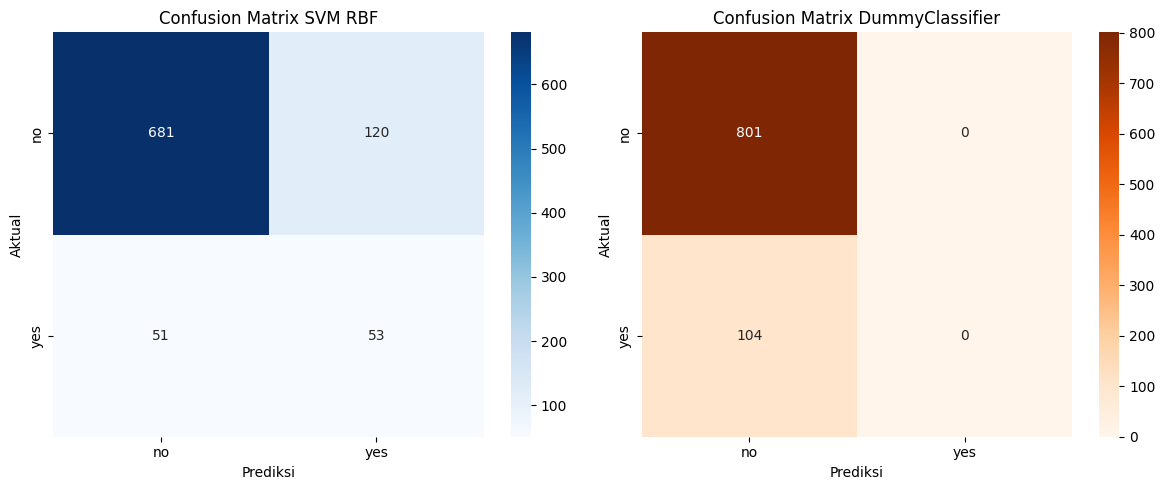

In [103]:

# ==========================================
# EVALUASI 4: CONFUSION MATRIX
# ==========================================

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix SVM
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=['no', 'yes']
)

sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['no', 'yes'],
    yticklabels=['no', 'yes'],
    ax=axes[0]
)

axes[0].set_title('Confusion Matrix SVM RBF')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

# Confusion Matrix Dummy
cm_dummy = confusion_matrix(
    y_test,
    y_pred_dummy,
    labels=['no', 'yes']
)

sns.heatmap(
    cm_dummy,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['no', 'yes'],
    yticklabels=['no', 'yes'],
    ax=axes[1]
)

axes[1].set_title('Confusion Matrix DummyClassifier')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()


In [104]:

# ==========================================
# EVALUASI 5: MEMERIKSA OVERFITTING
# ==========================================

# Prediksi data latih
prediksi_train = svm_model.predict(X_train)

# Prediksi data uji
prediksi_test = svm_model.predict(X_test)

akurasi_train = accuracy_score(
    y_train, prediksi_train
)

akurasi_test = accuracy_score(
    y_test, prediksi_test
)

print("Accuracy data latih:", round(akurasi_train, 4))
print("Accuracy data uji  :", round(akurasi_test, 4))

print(
    "Selisih accuracy:",
    round(akurasi_train - akurasi_test, 4)
)


Accuracy data latih: 0.8498
Accuracy data uji  : 0.811
Selisih accuracy: 0.0388


In [105]:

# ==========================================
# EVALUASI 6: NILAI CONFUSION MATRIX
# ==========================================

print("CONFUSION MATRIX SVM")
print(cm_svm)

print("\nCONFUSION MATRIX DUMMY")
print(cm_dummy)

# Mengambil nilai SVM
tn, fp, fn, tp = cm_svm.ravel()

print("\nRINCIAN CONFUSION MATRIX SVM")
print("True Negative :", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive :", tp)

# Menghitung precision, recall, dan F1 secara manual
precision_manual = tp / (tp + fp) if (tp + fp) else 0
recall_manual = tp / (tp + fn) if (tp + fn) else 0
f1_manual = (
    2 * precision_manual * recall_manual /
    (precision_manual + recall_manual)
    if (precision_manual + recall_manual) else 0
)

print("\nPERHITUNGAN MANUAL")
print("Precision:", precision_manual)
print("Recall   :", recall_manual)
print("F1-score :", f1_manual)


CONFUSION MATRIX SVM
[[681 120]
 [ 51  53]]

CONFUSION MATRIX DUMMY
[[801   0]
 [104   0]]

RINCIAN CONFUSION MATRIX SVM
True Negative : 681
False Positive: 120
False Negative: 51
True Positive : 53

PERHITUNGAN MANUAL
Precision: 0.3063583815028902
Recall   : 0.5096153846153846
F1-score : 0.3826714801444044


In [106]:

# ==========================================
# TAHAP 8: HYPERPARAMETER TUNING GRIDSEARCHCV
# ==========================================

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Menentukan metrik penilaian untuk kelas yes
f1_yes_scorer = make_scorer(f1_score, pos_label='yes')

# Menentukan kombinasi parameter yang akan diuji
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1],
    'classifier__class_weight': ['balanced', None]
}

# Membuat GridSearchCV
grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    scoring=f1_yes_scorer,
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Melatih dan mencari kombinasi parameter terbaik
grid_search.fit(X_train, y_train)

# Menampilkan hasil terbaik
print("PARAMETER TERBAIK:")
print(grid_search.best_params_)

print("\nF1-SCORE TERBAIK:")
print(grid_search.best_score_)


Fitting 5 folds for each of 32 candidates, totalling 160 fits
PARAMETER TERBAIK:
{'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 'scale'}

F1-SCORE TERBAIK:
0.36223992901081864


In [107]:

# ==========================================
# EVALUASI 8: PENGUJIAN MODEL TERBAIK
# ==========================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Mengambil model terbaik dari GridSearchCV
best_svm_model = grid_search.best_estimator_

# Melakukan prediksi pada data testing
y_pred_best = best_svm_model.predict(X_test)

# Menampilkan hasil evaluasi
print("HASIL EVALUASI MODEL SVM TERBAIK")
print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(
    y_test, y_pred_best, pos_label='yes'
))
print("Recall   :", recall_score(
    y_test, y_pred_best, pos_label='yes'
))
print("F1-score :", f1_score(
    y_test, y_pred_best, pos_label='yes'
))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred_best))

print("\nCONFUSION MATRIX")
cm_best = confusion_matrix(
    y_test, y_pred_best, labels=['no', 'yes']
)
print(cm_best)


HASIL EVALUASI MODEL SVM TERBAIK
Accuracy : 0.8110497237569061
Precision: 0.3063583815028902
Recall   : 0.5096153846153846
F1-score : 0.38267148014440433

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          no       0.93      0.85      0.89       801
         yes       0.31      0.51      0.38       104

    accuracy                           0.81       905
   macro avg       0.62      0.68      0.64       905
weighted avg       0.86      0.81      0.83       905


CONFUSION MATRIX
[[681 120]
 [ 51  53]]


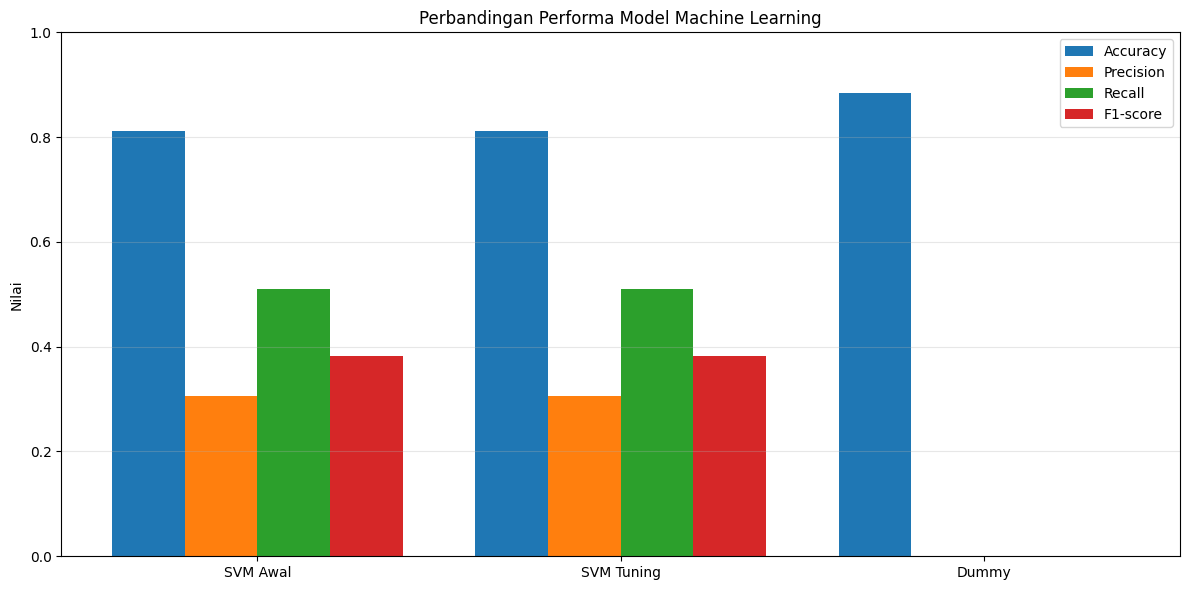

In [108]:

import matplotlib.pyplot as plt
import numpy as np

model_names = ['SVM Awal', 'SVM Tuning', 'Dummy']

accuracy_values = [0.8110, 0.8110, 0.8840]
precision_values = [0.3064, 0.3064, 0.0]
recall_values = [0.5096, 0.5096, 0.0]
f1_values = [0.3827, 0.3827, 0.0]

metrics = {
    'Accuracy': accuracy_values,
    'Precision': precision_values,
    'Recall': recall_values,
    'F1-score': f1_values
}

x = np.arange(len(model_names))
width = 0.2

plt.figure(figsize=(12, 6))

for i, (metric, values) in enumerate(metrics.items()):
    plt.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=metric
    )

plt.xticks(x, model_names)
plt.ylabel('Nilai')
plt.title('Perbandingan Performa Model Machine Learning')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### 1.3 Deskripsi Atribut Dataset

Dataset Bank Marketing yang digunakan terdiri dari 17 atribut yang menggambarkan karakteristik nasabah, informasi komunikasi pemasaran, riwayat kampanye sebelumnya, serta hasil akhir pemasaran. Berikut merupakan deskripsi masing-masing atribut.

| No. | Nama Atribut | Tipe Data | Deskripsi | Satuan |
|---:|---|---|---|---|
| 1 | age | Integer | Usia nasabah bank | Tahun |
| 2 | job | Kategorikal | Jenis pekerjaan nasabah, seperti management, technician, blue-collar, dan lainnya | Tidak ada |
| 3 | marital | Kategorikal | Status pernikahan nasabah, seperti married, single, dan divorced | Tidak ada |
| 4 | education | Kategorikal | Tingkat pendidikan terakhir nasabah | Tidak ada |
| 5 | default | Kategorikal | Menunjukkan apakah nasabah memiliki riwayat kredit gagal bayar | Tidak ada |
| 6 | balance | Integer | Saldo rata-rata tahunan nasabah | Satuan mata uang sumber data |
| 7 | housing | Kategorikal | Menunjukkan apakah nasabah memiliki pinjaman perumahan | Tidak ada |
| 8 | loan | Kategorikal | Menunjukkan apakah nasabah memiliki pinjaman pribadi | Tidak ada |
| 9 | contact | Kategorikal | Jenis komunikasi yang digunakan untuk menghubungi nasabah | Tidak ada |
| 10 | day | Integer | Hari dalam bulan ketika nasabah terakhir dihubungi | Hari |
| 11 | month | Kategorikal | Bulan ketika nasabah terakhir dihubungi | Bulan |
| 12 | duration | Integer | Durasi komunikasi terakhir antara bank dan nasabah | Detik |
| 13 | campaign | Integer | Jumlah kontak yang dilakukan selama kampanye pemasaran berlangsung | Kali |
| 14 | pdays | Integer | Jumlah hari sejak nasabah terakhir dihubungi dalam kampanye sebelumnya. Nilai -1 menunjukkan nasabah belum pernah dihubungi sebelumnya | Hari |
| 15 | previous | Integer | Jumlah kontak yang dilakukan sebelum kampanye pemasaran saat ini | Kali |
| 16 | poutcome | Kategorikal | Hasil dari kampanye pemasaran sebelumnya, seperti success, failure, other, atau unknown | Tidak ada |
| 17 | y | Kategorikal | Target klasifikasi yang menunjukkan apakah nasabah berlangganan deposito berjangka atau tidak. Nilai yes berarti berlangganan dan no berarti tidak | Tidak ada |

Berdasarkan tabel tersebut, atribut `y` digunakan sebagai variabel target dalam penelitian, sedangkan atribut lainnya merupakan informasi yang tersedia dalam dataset. Atribut `duration` tetap dijelaskan sebagai bagian dari dataset, tetapi tidak digunakan sebagai fitur dalam pemodelan untuk menghindari penggunaan informasi durasi panggilan yang baru diketahui setelah komunikasi berlangsung.
